In [ ]:
import torch
device = 'cuda' if int(torch.cuda.is_available()) == 1 else 'cpu'
device

'cuda'

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import optuna

import torch
import torchvision
import torchvision.transforms as transforms
import torchmetrics


In [ ]:
from torch.utils.data import random_split, DataLoader, TensorDataset, Dataset
from torch import nn
from torchmetrics.classification import MulticlassConfusionMatrix, MulticlassPrecisionRecallCurve

In [ ]:
train_data = torchvision.datasets.FashionMNIST(
    root='data', train=True, download=True,
    transform=transforms.ToTensor(),
)
test_data = torchvision.datasets.FashionMNIST(
    root='data', train=False, download=True,
    transform=transforms.ToTensor(),
)
len(test_data), len(train_data)

100%|██████████| 26.4M/26.4M [00:02<00:00, 12.4MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 202kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 3.73MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 13.2MB/s]


(10000, 60000)

In [ ]:
train_data, valid_data = random_split(dataset=train_data, lengths=[50000, 10000],
                                      generator=torch.Generator().manual_seed(26))
len(train_data), len(valid_data)

(50000, 10000)

In [ ]:
train_loader = DataLoader(
    train_data, batch_size=128, shuffle=True,
    drop_last=False, pin_memory=True, num_workers=2
)
valid_loader = DataLoader(valid_data, batch_size=128)
test_loader = DataLoader(test_data, batch_size=128)

In [ ]:
flatten_layer = nn.Flatten()
arr = torch.arange(0, 36).reshape(2, 2, 3, 3)
arr

tensor([[[[ 0,  1,  2],
          [ 3,  4,  5],
          [ 6,  7,  8]],

         [[ 9, 10, 11],
          [12, 13, 14],
          [15, 16, 17]]],


        [[[18, 19, 20],
          [21, 22, 23],
          [24, 25, 26]],

         [[27, 28, 29],
          [30, 31, 32],
          [33, 34, 35]]]])

In [ ]:
arr.shape

torch.Size([2, 2, 3, 3])

In [ ]:
flatten_layer(arr)

tensor([[ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17],
        [18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35]])

In [ ]:
flatten_layer = nn.Flatten()
arr = torch.arange(0, 18).reshape( 2, 3, 3)
arr

tensor([[[ 0,  1,  2],
         [ 3,  4,  5],
         [ 6,  7,  8]],

        [[ 9, 10, 11],
         [12, 13, 14],
         [15, 16, 17]]])

In [ ]:
flatten_layer(arr)

tensor([[ 0,  1,  2,  3,  4,  5,  6,  7,  8],
        [ 9, 10, 11, 12, 13, 14, 15, 16, 17]])

First dimension remains untouched during the flattening of layer


In [ ]:
class Classifier(nn.Module):
  def __init__(self, n_features, n_hidden_1, n_hidden_2, n_outputs):
    super().__init__()
    self.model = nn.Sequential(
        nn.Flatten(),
        nn.Linear(n_features, n_hidden_1),
        nn.LeakyReLU(negative_slope=0.01),
        nn.Linear(n_hidden_1, n_hidden_2),
        nn.LeakyReLU(negative_slope=0.01),
        nn.Linear(n_hidden_2, n_outputs)
    )
  def forward(self, X):
    return self.model(X)

  def train_and_validate(self, train_loader, valid_loader,
                         loss_function, optimizer, epochs):
    train_loss, valid_loss = [], []

    for i in range(epochs):
      self.train()
      train_epoch_loss, valid_epoch_loss = 0, 0
      for X_train, y_train in train_loader:
        X_train = X_train.to(device)
        y_train = y_train.to(device)
        loss = loss_function(self(X_train), y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_epoch_loss += loss.item()
      train_loss.append(train_epoch_loss/len(train_loader))

      self.eval()
      with torch.no_grad():
        for X_valid, y_valid in valid_loader:
          X_valid = X_valid.to(device)
          y_valid = y_valid.to(device)
          validation_loss = loss_function(self(X_valid), y_valid)
          valid_epoch_loss += validation_loss.item()
      valid_loss.append(valid_epoch_loss/len(valid_loader))

    plt.figure(figsize=(8, 6))
    plt.xlabel('Epochs')
    plt.ylabel('Average Loss')
    plt.plot(train_loss, label='train_loss', color='blue')
    plt.plot(valid_loss, label='valid_loss', color='red')
    plt.title('Train and Validation Loss')
    plt.legend()
    plt.show()

  def get_accuracy(self, test_loader):
    self.eval()
    with torch.no_grad():
      metric = torchmetrics.Accuracy(task='multiclass', num_classes=10).to(device)
      for X_test, y_test in test_loader:
        X_test = X_test.to(device)
        y_test = y_test.to(device)
        y_pred = self(X_test)
        metric.update(y_pred, y_test)
    return metric.compute()


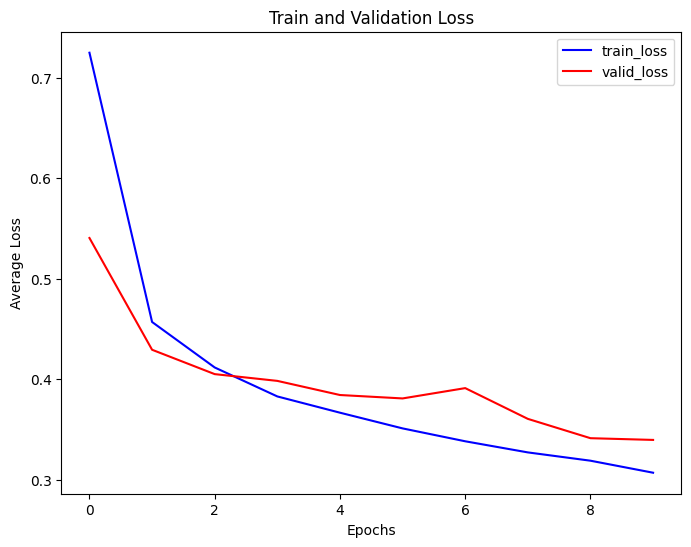

In [ ]:
model_1 = Classifier(n_features=784, n_hidden_1=64, n_hidden_2=32, n_outputs=10).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model_1.parameters(), lr=1e-3)
model_1.train_and_validate(train_loader, valid_loader, loss_fn, optimizer, 10)

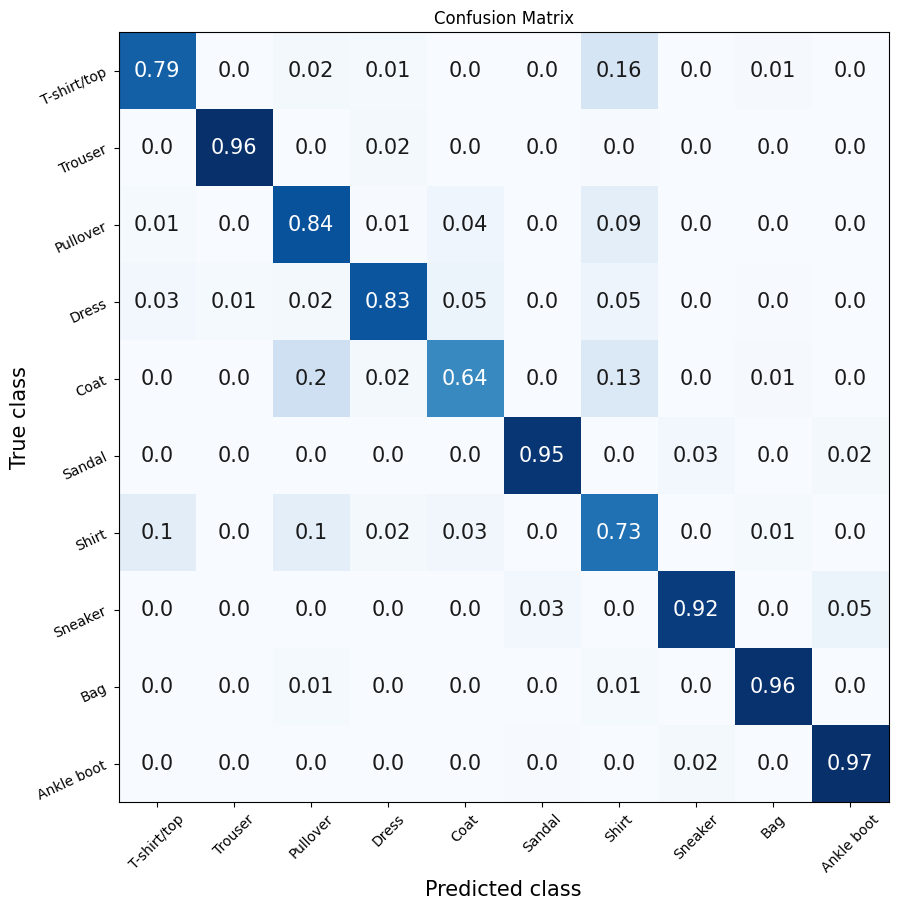

In [ ]:
metric_1 = MulticlassConfusionMatrix(num_classes=10, normalize='true').to(device)
metric_2 = MulticlassPrecisionRecallCurve(num_classes=10).to(device)
with torch.inference_mode():
  for X_test, y_test in test_loader:
    X_test = X_test.to(device)
    y_test = y_test.to(device)
    y_pred = model_1(X_test)
    metric_1.update(y_pred, y_test)
    metric_2.update(y_pred, y_test)
plt.figure(figsize=(10, 10))
metric_1.plot(labels=test_data.classes, cmap='Blues', ax=plt.gca())
plt.title('Confusion Matrix')
plt.show()

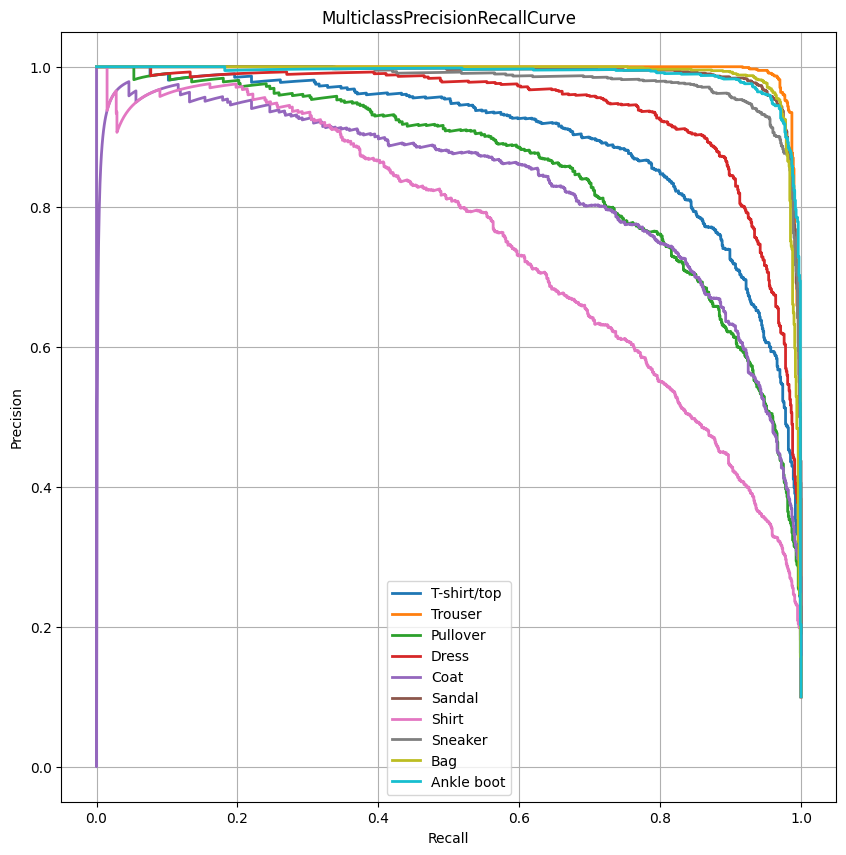

In [ ]:
plt.figure(figsize=(10, 10))
metric_2.plot(ax=plt.gca())
plt.legend(test_data.classes)
plt.show()

In [ ]:
class Classifier(nn.Module):
  def __init__(self, n_features, n_hidden_1, n_hidden_2, n_outputs, activation):
    super().__init__()
    if activation == 'LeakyReLU':
      act1 = nn.LeakyReLU(negative_slope=0.01)
      act2 = nn.LeakyReLU(negative_slope=0.01)
    else:
      act1 = nn.ReLU()
      act2 = nn.ReLU()

    self.model = nn.Sequential(
        nn.Flatten(),
        nn.Linear(n_features, n_hidden_1),
        act1,
        nn.Linear(n_hidden_1, n_hidden_2),
        act2,
        nn.Linear(n_hidden_2, n_outputs)
    )
  def forward(self, X):
    return self.model(X)

  def train_and_validate(self, train_loader, valid_loader,
                         loss_function, optimizer, epochs):
    train_loss, valid_loss = [], []

    for i in range(epochs):
      self.train()
      train_epoch_loss, valid_epoch_loss = 0, 0
      for X_train, y_train in train_loader:
        X_train = X_train.to(device)
        y_train = y_train.to(device)
        loss = loss_function(self(X_train), y_train)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_epoch_loss += loss.item()
      train_loss.append(train_epoch_loss/len(train_loader))

      self.eval()
      with torch.no_grad():
        for X_valid, y_valid in valid_loader:
          X_valid = X_valid.to(device)
          y_valid = y_valid.to(device)
          validation_loss = loss_function(self(X_valid), y_valid)
          valid_epoch_loss += validation_loss.item()
      valid_loss.append(valid_epoch_loss/len(valid_loader))

  def get_accuracy(self, test_loader):
    self.eval()
    with torch.no_grad():
      metric = torchmetrics.Accuracy(task='multiclass', num_classes=10).to(device)
      for X_test, y_test in test_loader:
        X_test = X_test.to(device)
        y_test = y_test.to(device)
        y_pred = self(X_test)
        metric.update(y_pred, y_test)
    return metric.compute()


In [ ]:
def objective(trial):    #This is objective function that optuna will optimize
  lr = trial.suggest_float('lr', 1e-5, 1e-2, log=True)      #The optuna uses it own algorithm where it first picks random lr then remember those to pick only best lr that maximizes the return score
  activation = trial.suggest_categorical('activation', ['LeakyReLU', 'ReLU'])
  model_2 = Classifier(784, 64, 32, 10, activation).to(device)
  loss_fn = nn.CrossEntropyLoss()
  optimizer = torch.optim.Adam(model_2.parameters(), lr=lr)
  model_2.train_and_validate(train_loader, valid_loader, loss_fn, optimizer, 10)
  accuracy = model_2.get_accuracy(valid_loader)
  return accuracy.item()      #Optuna will optimize this using its own mathematical algorithm

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=8)

[I 2026-11-09 10:20:24,692] A new study created in memory with name: no-name-eeb59521-04da-4a8a-9f96-606f18e9e3b2
[I 2026-11-09 10:21:36,007] Trial 0 finished with value: 0.8166000247001648 and parameters: {'lr': 4.519269247115211e-05, 'activation': 'ReLU'}. Best is trial 0 with value: 0.8166000247001648.
[I 2026-11-09 10:22:46,370] Trial 1 finished with value: 0.7907999753952026 and parameters: {'lr': 3.081526757363499e-05, 'activation': 'ReLU'}. Best is trial 0 with value: 0.8166000247001648.
[I 2026-11-09 10:23:56,343] Trial 2 finished with value: 0.7056000232696533 and parameters: {'lr': 1.3326169054430439e-05, 'activation': 'ReLU'}. Best is trial 0 with value: 0.8166000247001648.
[I 2026-11-09 10:25:07,934] Trial 3 finished with value: 0.8517000079154968 and parameters: {'lr': 0.00012866507480315922, 'activation': 'ReLU'}. Best is trial 3 with value: 0.8517000079154968.
[I 2026-11-09 10:26:19,476] Trial 4 finished with value: 0.8805000185966492 and parameters: {'lr': 0.00208880122

In [ ]:
optuna.visualization.plot_optimization_history(study)

Exception ignored in: <function _ConnectionBase.__del__ at 0x7ff6890c9bc0>
Traceback (most recent call last):
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 138, in __del__
    self._close()
  File "/usr/lib/python3.13/multiprocessing/connection.py", line 382, in _close
    _close(self._handle)
OSError: [Errno 9] Bad file descriptor


In [ ]:
 optuna.visualization.plot_param_importances(study)

In [ ]:
optuna.visualization.plot_slice(study, params=['activation'])


In [ ]:
optuna.visualization.plot_slice(study, params=['lr'])


In [ ]:
study.best_params

{'lr': 0.002088801229121086, 'activation': 'ReLU'}

In [ ]:
study.best_value

0.8805000185966492

In [ ]:
model_1.get_accuracy(valid_loader)

tensor(0.8787, device='cuda:0')

In [ ]:
model_1.get_accuracy(test_loader)

tensor(0.8695, device='cuda:0')

In [ ]:
# We need to train the model again with the best parameter found by study and retrain and save it which might need more time

In [ ]:
model_1.state_dict()

OrderedDict([('model.1.weight',
              tensor([[-0.1365,  0.1975,  0.3357,  ...,  0.0542, -0.0056,  0.1776],
                      [ 0.0899,  0.0826,  0.2668,  ..., -0.1199, -0.1546, -0.0274],
                      [-0.0351,  0.1338,  0.0983,  ...,  0.1846,  0.1656,  0.2852],
                      ...,
                      [ 0.1361, -0.1426, -0.2305,  ..., -0.1036, -0.0656, -0.1127],
                      [-0.0921, -0.1816, -0.2719,  ..., -0.2821, -0.2025, -0.2335],
                      [ 0.2488,  0.1648,  0.3203,  ...,  0.1367,  0.1326,  0.4674]],
                     device='cuda:0')),
             ('model.1.bias',
              tensor([ 0.0145, -0.0616,  0.1882, -0.1557, -0.1587,  0.1184,  0.2044, -0.0240,
                       0.3276, -0.2796,  0.3266,  0.0706,  0.5802,  0.1001, -0.0340,  0.4922,
                      -0.1715,  0.5067,  0.2006,  0.0555, -0.2865,  0.2796,  0.0284,  0.1850,
                       0.2736,  0.0784,  0.0463,  0.1951,  0.0448, -0.2154,  0.1893,

In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
from google.colab import drive
drive.mount('/content/drive')